In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import LinearSVC
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, confusion_matrix, classification_report
)

import warnings
warnings.filterwarnings("ignore")

In [ ]:
from google.colab import files

uploaded = files.upload()

Saving emails.csv to emails.csv


In [ ]:
filename = next(iter(uploaded))
df = pd.read_csv(filename)

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (5172, 3002)


,Email No.,the,to,ect,and,for,of,a,you,hou,...,connevey,jay,valued,lay,infrastructure,military,allowing,ff,dry,Prediction
0,Email 1,0,0,1,0,0,0,2,0,0,...,0,0,0,0,0,0,0,0,0,0
1,Email 2,8,13,24,6,6,2,102,1,27,...,0,0,0,0,0,0,0,1,0,0
2,Email 3,0,0,1,0,0,0,8,0,0,...,0,0,0,0,0,0,0,0,0,0
3,Email 4,0,5,22,0,5,1,51,2,10,...,0,0,0,0,0,0,0,0,0,0
4,Email 5,7,6,17,1,5,2,57,0,9,...,0,0,0,0,0,0,0,1,0,0


In [ ]:
print("Missing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())
print("Columns:", df.shape[1])

Missing values: 0
Duplicate rows: 0
Columns: 3002


In [ ]:
df = df.drop_duplicates().dropna().copy()

target = df.columns[-1]

X = df.drop(columns=[target])

if str(X.columns[0]).strip().lower() in [
    "email no.", "email no", "email", "email_id", "email id"
]:
    X = X.iloc[:, 1:]

X = X.apply(pd.to_numeric, errors="coerce").fillna(0)
y = pd.to_numeric(df[target], errors="coerce")

valid = y.isin([0, 1])
X = X.loc[valid]
y = y.loc[valid].astype(int)

print("Features:", X.shape)
print("Labels:", y.shape)
print(y.value_counts())

Features: (5172, 3000)
Labels: (5172,)
Prediction
0    3672
1    1500
Name: count, dtype: int64


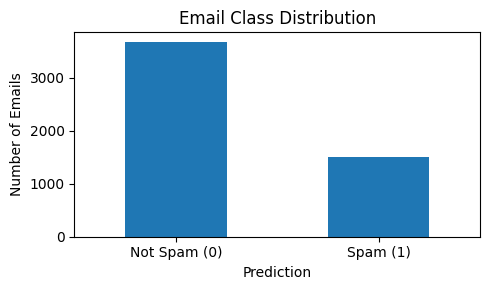

In [ ]:
y.value_counts().sort_index().plot(
    kind="bar", figsize=(5, 3)
)

plt.xticks([0, 1], ["Not Spam (0)", "Spam (1)"], rotation=0)
plt.title("Email Class Distribution")
plt.ylabel("Number of Emails")
plt.tight_layout()
plt.show()

In [ ]:
MAX_ROWS = 2500

if len(X) > MAX_ROWS:
    X, _, y, _ = train_test_split(
        X, y,
        train_size=MAX_ROWS,
        random_state=42,
        stratify=y
    )

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))

Training rows: 2000
Testing rows: 500


In [ ]:
from sklearn.preprocessing import MaxAbsScaler

scaler = MaxAbsScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Scaling completed.")

Scaling completed.


In [ ]:
knn = KNeighborsClassifier(
    n_neighbors=3,
    n_jobs=-1
)

knn.fit(X_train_scaled, y_train)
knn_pred = knn.predict(X_test_scaled)

print("KNN completed.")

KNN completed.


In [ ]:
svm = LinearSVC(
    C=1.0,
    max_iter=500,
    random_state=42,
    dual="auto"
)

svm.fit(X_train_scaled, y_train)
svm_pred = svm.predict(X_test_scaled)

print("SVM completed.")

SVM completed.


In [ ]:
def evaluate(name, actual, predicted):
    tn, fp, fn, tp = confusion_matrix(
        actual, predicted, labels=[0, 1]
    ).ravel()

    return {
        "Model": name,
        "Accuracy": accuracy_score(actual, predicted),
        "Precision": precision_score(
            actual, predicted, zero_division=0
        ),
        "Recall": recall_score(
            actual, predicted, zero_division=0
        ),
        "F1 Score": f1_score(
            actual, predicted, zero_division=0
        ),
        "Specificity": tn / (tn + fp) if tn + fp else 0,
        "Error Rate": (fp + fn) / (tp + tn + fp + fn)
    }


results = pd.DataFrame([
    evaluate("KNN", y_test, knn_pred),
    evaluate("SVM", y_test, svm_pred)
])

display(results.round(4))

,Model,Accuracy,Precision,Recall,F1 Score,Specificity,Error Rate
0,KNN,0.798,0.5991,0.9172,0.7248,0.7493,0.202
1,SVM,0.946,0.8782,0.9448,0.9103,0.9465,0.054


In [ ]:
print("KNN Report")
print(classification_report(
    y_test, knn_pred,
    target_names=["Not Spam", "Spam"],
    zero_division=0
))

print("SVM Report")
print(classification_report(
    y_test, svm_pred,
    target_names=["Not Spam", "Spam"],
    zero_division=0
))

KNN Report
              precision    recall  f1-score   support

    Not Spam       0.96      0.75      0.84       355
        Spam       0.60      0.92      0.72       145

    accuracy                           0.80       500
   macro avg       0.78      0.83      0.78       500
weighted avg       0.85      0.80      0.81       500

SVM Report
              precision    recall  f1-score   support

    Not Spam       0.98      0.95      0.96       355
        Spam       0.88      0.94      0.91       145

    accuracy                           0.95       500
   macro avg       0.93      0.95      0.94       500
weighted avg       0.95      0.95      0.95       500



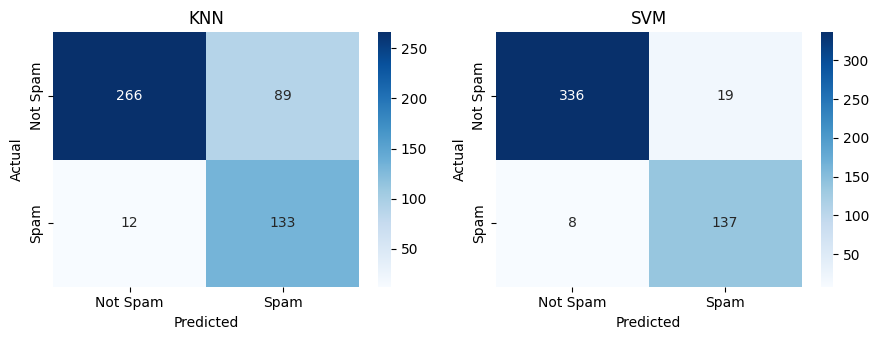

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.5))

for ax, name, pred in zip(
    axes, ["KNN", "SVM"], [knn_pred, svm_pred]
):
    sns.heatmap(
        confusion_matrix(y_test, pred, labels=[0, 1]),
        annot=True, fmt="d", cmap="Blues", ax=ax,
        xticklabels=["Not Spam", "Spam"],
        yticklabels=["Not Spam", "Spam"]
    )
    ax.set_title(name)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")

plt.tight_layout()
plt.savefig("confusion_matrices.png", dpi=200)
plt.show()

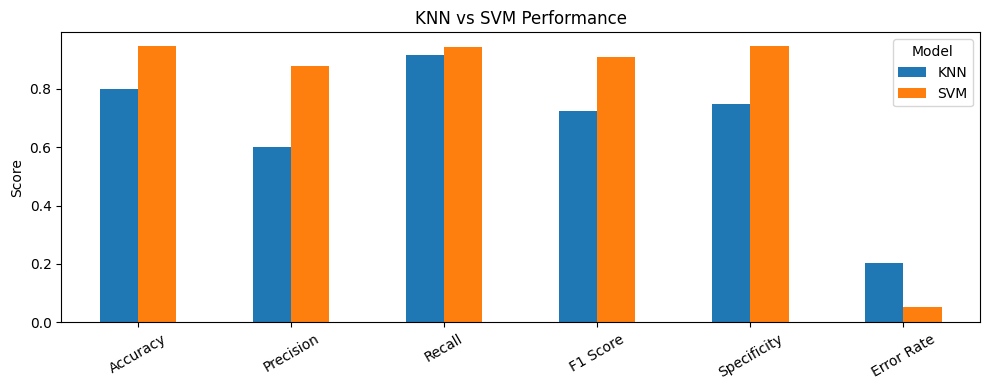

In [ ]:
results.set_index("Model").T.plot(
    kind="bar", figsize=(10, 4)
)

plt.title("KNN vs SVM Performance")
plt.ylabel("Score")
plt.xticks(rotation=30)
plt.tight_layout()

plt.savefig("classification_comparison.png", dpi=200)
plt.show()

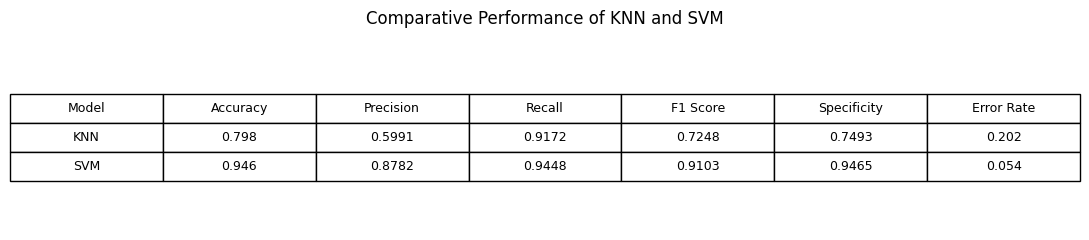

In [ ]:
fig, ax = plt.subplots(figsize=(11, 2.5))
ax.axis("off")

table = ax.table(
    cellText=results.round(4).values,
    colLabels=results.columns,
    cellLoc="center",
    loc="center"
)

table.auto_set_font_size(False)
table.set_fontsize(9)
table.scale(1, 1.8)

plt.title("Comparative Performance of KNN and SVM", pad=15)
plt.tight_layout()

plt.savefig(
    "email_spam_result.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()